<a href="https://colab.research.google.com/github/asheta66/Applications/blob/main/ViT_Potato_Leaf_Classification_128.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# Improved Vision Transformer (ViT) from Scratch for Chest X-Ray Classification

This notebook trains a **Vision Transformer from scratch** to classify chest X-rays as **NORMAL** or **PNEUMONIA**.

### Main improvements over the original notebook
- Uses the **full available dataset** instead of limiting each class to 100 images.
- Uses medically more reasonable augmentation (small rotation, translation, zoom, brightness changes; no vertical flips or 90°/180° rotations).
- Uses **16×16 patches** instead of 7×7 patches, using 64 patches for 128×128 RGB images (8×8 patch grid).
- Uses a smaller, more data-appropriate ViT with **4 Transformer blocks**.
- Uses the correct per-head attention dimension.
- Replaces `Flatten()` with `GlobalAveragePooling1D()` to greatly reduce classifier parameters and overfitting.
- Uses **AdamW** with weight decay and cosine learning-rate decay.
- Uses class weights to address class imbalance without discarding images.
- Tracks accuracy, ROC-AUC, precision, and recall.
- Selects the best model using **validation AUC**.
- Evaluates only once on the held-out test set after training.
- Produces a confusion matrix, classification report, sensitivity, specificity, ROC curve, and training curves.

> **Important:** This is still a ViT trained from scratch. A pretrained ViT/CNN will generally perform better on a dataset of this size, but this notebook keeps the from-scratch requirement.


## 1. Libraries and Reproducibility

In [ ]:
import os
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    average_precision_score,
    precision_recall_curve,
    roc_curve,
)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers as L

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# Reproducibility
# ------------------------------------------------------------
RANDOM_STATE = 42
os.environ["PYTHONHASHSEED"] = str(RANDOM_STATE)
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)

# ------------------------------------------------------------
# Optional GPU optimization
# ------------------------------------------------------------
GPU_DEVICES = tf.config.list_physical_devices("GPU")
USE_MIXED_PRECISION = len(GPU_DEVICES) > 0

if USE_MIXED_PRECISION:
    from tensorflow.keras import mixed_precision
    mixed_precision.set_global_policy("mixed_float16")

# ------------------------------------------------------------
# Compact plotting defaults
# ------------------------------------------------------------
plt.rcParams.update({
    "figure.figsize": (6, 4),
    "figure.dpi": 110,
    "axes.titlesize": 10,
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
})

print("=" * 70)
print("ENVIRONMENT")
print("=" * 70)
print("TensorFlow version :", tf.__version__)
print("GPU devices        :", GPU_DEVICES)
print("Mixed precision    :", USE_MIXED_PRECISION)
print("Random seed        :", RANDOM_STATE)

ENVIRONMENT
TensorFlow version : 2.20.0
GPU devices        : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Mixed precision    : True
Random seed        : 42


## 2. Mount Google Drive and Build the Full Dataset

In [ ]:
from google.colab import drive

MOUNT_POINT = "/content/mydrive"
drive.mount(MOUNT_POINT)

# ------------------------------------------------------------
# Dataset configuration
# ------------------------------------------------------------
IMAGE_SIZE = 128
BATCH_SIZE = 16
N_CLASSES = 2
RANDOM_STATE = 42

DRIVE_DATA_DIR = Path(f"{MOUNT_POINT}/MyDrive/Chest X_Ray")

NORMAL_DIR = DRIVE_DATA_DIR / "NORMAL"
PNEUMONIA_DIR = DRIVE_DATA_DIR / "PNEUMONIA"

OUTPUT_DIR = Path(
    f"{MOUNT_POINT}/MyDrive/Chest_XRay_ViT_Results_Optimized"
)
FIGURE_DIR = OUTPUT_DIR / "figures"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

CLASS_NAMES = ["NORMAL", "PNEUMONIA"]

SUPPORTED_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"
}

def save_figure(fig, filename):
    path = FIGURE_DIR / filename
    fig.savefig(path, dpi=220, bbox_inches="tight")
    print("Saved figure:", path)
    return path

def find_image_files(folder):
    return sorted([
        p for p in folder.rglob("*")
        if p.is_file() and p.suffix.lower() in SUPPORTED_EXTENSIONS
    ])

if not DRIVE_DATA_DIR.exists():
    raise FileNotFoundError(
        f"Dataset folder not found: {DRIVE_DATA_DIR}"
    )

if not NORMAL_DIR.exists():
    raise FileNotFoundError(
        f"NORMAL folder not found: {NORMAL_DIR}"
    )

if not PNEUMONIA_DIR.exists():
    raise FileNotFoundError(
        f"PNEUMONIA folder not found: {PNEUMONIA_DIR}"
    )

normal_files = find_image_files(NORMAL_DIR)
pneumonia_files = find_image_files(PNEUMONIA_DIR)

if len(normal_files) == 0 or len(pneumonia_files) == 0:
    raise ValueError(
        "One or both class folders contain no supported images."
    )

data = (
    [
        {
            "image_path": str(p),
            "label": 0,
            "class_name": "NORMAL"
        }
        for p in normal_files
    ]
    +
    [
        {
            "image_path": str(p),
            "label": 1,
            "class_name": "PNEUMONIA"
        }
        for p in pneumonia_files
    ]
)

df = (
    pd.DataFrame(data)
    .sample(frac=1, random_state=RANDOM_STATE)
    .reset_index(drop=True)
)

dataset_summary_df = pd.DataFrame({
    "Class": CLASS_NAMES,
    "Count": [
        int((df["label"] == 0).sum()),
        int((df["label"] == 1).sum()),
    ]
})
dataset_summary_df["Percent"] = (
    100 * dataset_summary_df["Count"] / len(df)
)

print("=" * 70)
print("FULL CHEST X-RAY DATASET")
print("=" * 70)
display(dataset_summary_df.round(2))
print(f"Total images: {len(df):,}")
display(df.head())
print("Output directory:", OUTPUT_DIR)
print("Figure directory:", FIGURE_DIR)

Mounted at /content/mydrive
FULL CHEST X-RAY DATASET


,Class,Count,Percent
0,NORMAL,1583,27.03
1,PNEUMONIA,4273,72.97


Total images: 5,856


,image_path,label,class_name
0,/content/mydrive/MyDrive/Chest X_Ray/PNEUMONIA...,1,PNEUMONIA
1,/content/mydrive/MyDrive/Chest X_Ray/PNEUMONIA...,1,PNEUMONIA
2,/content/mydrive/MyDrive/Chest X_Ray/NORMAL/NO...,0,NORMAL
3,/content/mydrive/MyDrive/Chest X_Ray/NORMAL/NO...,0,NORMAL
4,/content/mydrive/MyDrive/Chest X_Ray/NORMAL/NO...,0,NORMAL


Output directory: /content/mydrive/MyDrive/Chest_XRay_ViT_Results_Optimized
Figure directory: /content/mydrive/MyDrive/Chest_XRay_ViT_Results_Optimized/figures


## 3. Stratified Train / Validation / Test Split

In [ ]:
# ============================================================
# Stratified Train / Validation / Test split
# ============================================================

# 70% train, 15% validation, 15% test
df_train, df_temp = train_test_split(
    df,
    test_size=0.30,
    stratify=df["label"],
    random_state=RANDOM_STATE,
)

df_valid, df_test = train_test_split(
    df_temp,
    test_size=0.50,
    stratify=df_temp["label"],
    random_state=RANDOM_STATE,
)

df_train = df_train.reset_index(drop=True)
df_valid = df_valid.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

def summarize_split(name, frame):
    counts = (
        frame["class_name"]
        .value_counts()
        .reindex(CLASS_NAMES, fill_value=0)
    )
    return {
        "Split": name,
        "Total": len(frame),
        "NORMAL": int(counts["NORMAL"]),
        "PNEUMONIA": int(counts["PNEUMONIA"]),
        "Pneumonia_%": round(100 * frame["label"].mean(), 2),
    }

split_summary_df = pd.DataFrame([
    summarize_split("Train", df_train),
    summarize_split("Validation", df_valid),
    summarize_split("Test", df_test),
])

print("=" * 70)
print("DATASET SPLIT")
print("=" * 70)
display(split_summary_df)

df_train.to_csv(OUTPUT_DIR / "train_split.csv", index=False)
df_valid.to_csv(OUTPUT_DIR / "validation_split.csv", index=False)
df_test.to_csv(OUTPUT_DIR / "test_split.csv", index=False)
split_summary_df.to_csv(
    OUTPUT_DIR / "split_summary.csv",
    index=False
)

DATASET SPLIT


,Split,Total,NORMAL,PNEUMONIA,Pneumonia_%
0,Train,4099,1108,2991,72.97
1,Validation,878,237,641,73.01
2,Test,879,238,641,72.92


## 4. Data Generators and Medically Conservative Augmentation

In [ ]:
# ============================================================
# Data augmentation and image generators
# ============================================================
# Augmentation is deliberately conservative for chest X-rays:
# - small rotations
# - small translations
# - modest zoom
# - modest brightness variation
#
# No vertical flips and no 90/180/270-degree rotations because
# these can create anatomically unrealistic chest radiographs.
#
# Class imbalance is handled separately with class weights.

train_datagen = tf.keras.preprocessing.image.ImageDataGenerator(
    rescale=1.0 / 255.0,
    rotation_range=7,
    width_shift_range=0.05,
    height_shift_range=0.05,
    zoom_range=0.08,
    brightness_range=(0.90, 1.10),
    fill_mode="nearest",
)

eval_datagen = tf.keras.preprocessing.image.ImageDataGenerator(
    rescale=1.0 / 255.0
)

train_gen = train_datagen.flow_from_dataframe(
    dataframe=df_train,
    x_col="image_path",
    y_col="class_name",
    classes=CLASS_NAMES,
    target_size=(IMAGE_SIZE, IMAGE_SIZE),
    batch_size=BATCH_SIZE,
    class_mode="binary",
    color_mode="rgb",
    shuffle=True,
    seed=RANDOM_STATE,
)

# Non-augmented and non-shuffled generator for final TRAIN evaluation.
train_eval_gen = eval_datagen.flow_from_dataframe(
    dataframe=df_train,
    x_col="image_path",
    y_col="class_name",
    classes=CLASS_NAMES,
    target_size=(IMAGE_SIZE, IMAGE_SIZE),
    batch_size=BATCH_SIZE,
    class_mode="binary",
    color_mode="rgb",
    shuffle=False,
)

valid_gen = eval_datagen.flow_from_dataframe(
    dataframe=df_valid,
    x_col="image_path",
    y_col="class_name",
    classes=CLASS_NAMES,
    target_size=(IMAGE_SIZE, IMAGE_SIZE),
    batch_size=BATCH_SIZE,
    class_mode="binary",
    color_mode="rgb",
    shuffle=False,
)

test_gen = eval_datagen.flow_from_dataframe(
    dataframe=df_test,
    x_col="image_path",
    y_col="class_name",
    classes=CLASS_NAMES,
    target_size=(IMAGE_SIZE, IMAGE_SIZE),
    batch_size=BATCH_SIZE,
    class_mode="binary",
    color_mode="rgb",
    shuffle=False,
)

print("=" * 70)
print("DATA AUGMENTATION / GENERATORS")
print("=" * 70)
print("Class indices:", train_gen.class_indices)
print("Training samples   :", train_gen.n)
print("Validation samples :", valid_gen.n)
print("Test samples       :", test_gen.n)
print("Training augmentation enabled: YES")
print("Validation/Test augmentation : NO")
# ------------------------------------------------------------
# Verify preprocessing output shape explicitly
# ------------------------------------------------------------
_shape_images, _shape_labels = next(train_eval_gen)
EXPECTED_IMAGE_SHAPE = (IMAGE_SIZE, IMAGE_SIZE, 3)
if tuple(_shape_images.shape[1:]) != EXPECTED_IMAGE_SHAPE:
    raise ValueError(
        f"Unexpected image shape: {_shape_images.shape[1:]}; "
        f"expected {EXPECTED_IMAGE_SHAPE}"
    )
print("Verified preprocessed image shape:", _shape_images.shape[1:])
train_eval_gen.reset()


Found 4099 validated image filenames belonging to 2 classes.
Found 4099 validated image filenames belonging to 2 classes.
Found 878 validated image filenames belonging to 2 classes.
Found 879 validated image filenames belonging to 2 classes.
DATA AUGMENTATION / GENERATORS
Class indices: {'NORMAL': 0, 'PNEUMONIA': 1}
Training samples   : 4099
Validation samples : 878
Test samples       : 879
Training augmentation enabled: YES
Validation/Test augmentation : NO
Verified preprocessed image shape: (128, 128, 3)


## 5. Compute Class Weights

In [ ]:
# ============================================================
# Class-imbalance handling
# ============================================================
# Keep all training images and compensate for imbalance with
# dynamically calculated class weights.

class_ids = np.array(sorted(df_train["label"].unique()))

weights = compute_class_weight(
    class_weight="balanced",
    classes=class_ids,
    y=df_train["label"].values,
)

class_weight = {
    int(cls): float(w)
    for cls, w in zip(class_ids, weights)
}

class_weight_df = pd.DataFrame({
    "Class_ID": list(class_weight.keys()),
    "Class_Name": [
        CLASS_NAMES[int(i)] for i in class_weight.keys()
    ],
    "Weight": list(class_weight.values()),
})

print("=" * 70)
print("CLASS WEIGHTS")
print("=" * 70)
display(class_weight_df.round(4))
class_weight_df.to_csv(
    OUTPUT_DIR / "class_weights.csv",
    index=False
)

CLASS WEIGHTS


,Class_ID,Class_Name,Weight
0,0,NORMAL,1.8497
1,1,PNEUMONIA,0.6852


## 6. Visualize Sample Training Images

Saved figure: /content/mydrive/MyDrive/Chest_XRay_ViT_Results_Optimized/figures/01_augmented_training_examples.png


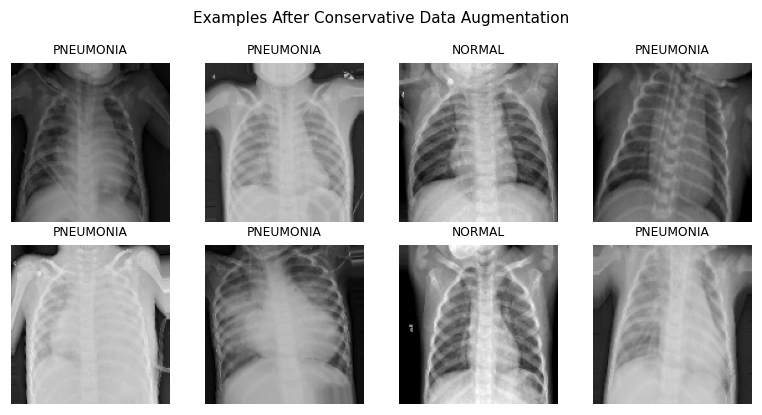

In [ ]:
# ============================================================
# Visual check of AUGMENTED training images
# ============================================================

images, labels = next(train_gen)

n_show = min(8, len(images))
fig, axes = plt.subplots(2, 4, figsize=(7.2, 3.8))
axes = axes.ravel()

for i in range(n_show):
    axes[i].imshow(np.clip(np.asarray(images[i], dtype=np.float32), 0, 1))
    axes[i].set_title(
        CLASS_NAMES[int(labels[i])],
        fontsize=8
    )
    axes[i].axis("off")

for ax in axes[n_show:]:
    ax.axis("off")

fig.suptitle(
    "Examples After Conservative Data Augmentation",
    fontsize=10
)
fig.tight_layout()

save_figure(
    fig,
    "01_augmented_training_examples.png"
)

plt.show()
plt.close(fig)

# Reset so visualization does not affect training position.
train_gen.reset()

## 7. ViT Hyperparameters

In [ ]:

PATCH_SIZE = 16

if IMAGE_SIZE % PATCH_SIZE != 0:
    raise ValueError(
        f"IMAGE_SIZE ({IMAGE_SIZE}) must be divisible by PATCH_SIZE ({PATCH_SIZE})."
    )
NUM_PATCHES = (IMAGE_SIZE // PATCH_SIZE) ** 2

PROJECTION_DIM = 64
NUM_HEADS = 4
TRANSFORMER_LAYERS = 4

TRANSFORMER_UNITS = [
    PROJECTION_DIM * 2,
    PROJECTION_DIM,
]

MLP_HEAD_UNITS = [128, 64]

LEARNING_RATE = 3e-4
WEIGHT_DECAY = 1e-4
EPOCHS = 40

print(f"Image size          : {IMAGE_SIZE} x {IMAGE_SIZE}")
print(f"Patch size          : {PATCH_SIZE} x {PATCH_SIZE}")
print(f"Number of patches   : {NUM_PATCHES}")
print(f"Projection dimension: {PROJECTION_DIM}")
print(f"Attention heads     : {NUM_HEADS}")
print(f"Transformer blocks  : {TRANSFORMER_LAYERS}")


Image size          : 128 x 128
Patch size          : 16 x 16
Number of patches   : 64
Projection dimension: 64
Attention heads     : 4
Transformer blocks  : 4


## 8. MLP, Patch Extraction, and Positional Encoding

In [ ]:

def mlp(x, hidden_units, dropout_rate):
    for units in hidden_units:
        x = L.Dense(units, activation=tf.nn.gelu)(x)
        x = L.Dropout(dropout_rate)(x)
    return x


class Patches(L.Layer):
    def __init__(self, patch_size, **kwargs):
        super().__init__(**kwargs)
        self.patch_size = patch_size

    def call(self, images):
        batch_size = tf.shape(images)[0]

        patches = tf.image.extract_patches(
            images=images,
            sizes=[1, self.patch_size, self.patch_size, 1],
            strides=[1, self.patch_size, self.patch_size, 1],
            rates=[1, 1, 1, 1],
            padding="VALID",
        )

        patch_dims = patches.shape[-1]
        patches = tf.reshape(patches, [batch_size, -1, patch_dims])
        return patches

    def get_config(self):
        config = super().get_config()
        config.update({"patch_size": self.patch_size})
        return config


class PatchEncoder(L.Layer):
    def __init__(self, num_patches, projection_dim, **kwargs):
        super().__init__(**kwargs)
        self.num_patches = num_patches
        self.projection_dim = projection_dim

        self.projection = L.Dense(projection_dim)
        self.position_embedding = L.Embedding(
            input_dim=num_patches,
            output_dim=projection_dim,
        )

    def call(self, patches):
        positions = tf.range(start=0, limit=self.num_patches, delta=1)
        return self.projection(patches) + self.position_embedding(positions)

    def get_config(self):
        config = super().get_config()
        config.update({
            "num_patches": self.num_patches,
            "projection_dim": self.projection_dim,
        })
        return config


## 9. Visualize the 16×16 Patch Grid

Patch tensor shape: (1, 64, 768)
Patches per image : 64
Saved figure: /content/mydrive/MyDrive/Chest_XRay_ViT_Results_Optimized/figures/02_vit_image_patches.png


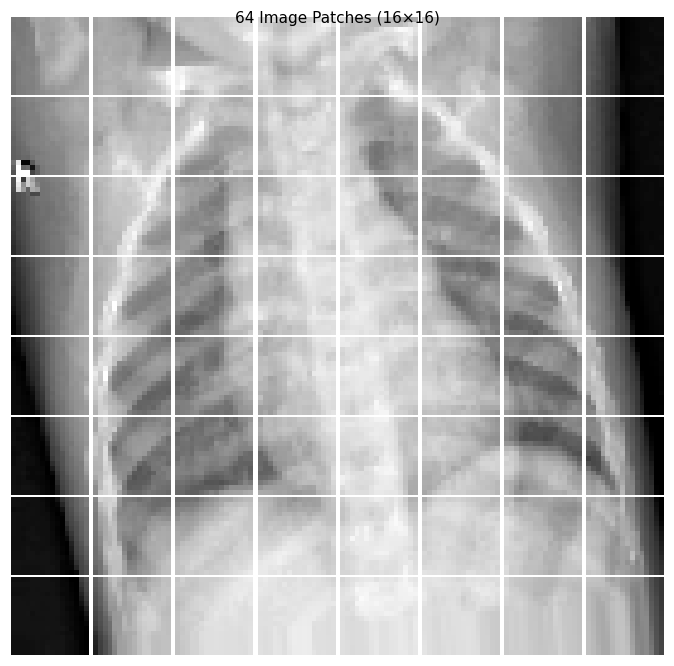

In [ ]:
# ============================================================
# Visualize ViT patches
# ============================================================

sample_images, _ = next(train_gen)
sample_image = sample_images[0]

patch_tensor = Patches(PATCH_SIZE)(
    tf.expand_dims(sample_image, axis=0)
)

# Matplotlib cannot render float16 image arrays. With mixed precision
# enabled, the custom layer may output float16, so cast once for plotting.
patch_tensor_for_plot = tf.cast(patch_tensor, tf.float32)

print("Patch tensor shape:", patch_tensor.shape)
print("Patches per image :", patch_tensor.shape[1])

grid_size = IMAGE_SIZE // PATCH_SIZE

fig, axes = plt.subplots(
    grid_size,
    grid_size,
    figsize=(6.0, 6.0)
)

axes = np.asarray(axes).ravel()

for i, patch in enumerate(patch_tensor_for_plot[0]):
    patch_img = tf.reshape(
        patch,
        (PATCH_SIZE, PATCH_SIZE, 3)
    )
    axes[i].imshow(
        np.clip(patch_img.numpy(), 0, 1)
    )
    axes[i].axis("off")

fig.suptitle(
    f"{NUM_PATCHES} Image Patches "
    f"({PATCH_SIZE}×{PATCH_SIZE})",
    fontsize=10
)
fig.tight_layout(pad=0.15)

save_figure(
    fig,
    "02_vit_image_patches.png"
)

plt.show()
plt.close(fig)

train_gen.reset()

## 10. Build the Improved Vision Transformer

In [ ]:

def build_vit_classifier():
    inputs = L.Input(shape=(IMAGE_SIZE, IMAGE_SIZE, 3))

    # Patch extraction and encoding
    patches = Patches(PATCH_SIZE, name="patches")(inputs)
    encoded_patches = PatchEncoder(
        NUM_PATCHES,
        PROJECTION_DIM,
        name="patch_encoder",
    )(patches)

    # Transformer encoder blocks
    for block_idx in range(TRANSFORMER_LAYERS):
        x1 = L.LayerNormalization(
            epsilon=1e-6,
            name=f"block_{block_idx + 1}_ln1",
        )(encoded_patches)

        attention_output = L.MultiHeadAttention(
            num_heads=NUM_HEADS,
            key_dim=PROJECTION_DIM // NUM_HEADS,
            dropout=0.1,
            name=f"block_{block_idx + 1}_attention",
        )(x1, x1)

        x2 = L.Add(
            name=f"block_{block_idx + 1}_skip1"
        )([encoded_patches, attention_output])

        x3 = L.LayerNormalization(
            epsilon=1e-6,
            name=f"block_{block_idx + 1}_ln2",
        )(x2)

        x3 = mlp(
            x3,
            hidden_units=TRANSFORMER_UNITS,
            dropout_rate=0.1,
        )

        encoded_patches = L.Add(
            name=f"block_{block_idx + 1}_skip2"
        )([x2, x3])

    # Compact image representation instead of Flatten().
    representation = L.LayerNormalization(
        epsilon=1e-6,
        name="final_layer_norm",
    )(encoded_patches)

    representation = L.GlobalAveragePooling1D(
        name="global_average_pooling"
    )(representation)

    representation = L.Dropout(0.30)(representation)

    features = mlp(
        representation,
        hidden_units=MLP_HEAD_UNITS,
        dropout_rate=0.30,
    )

    outputs = L.Dense(
        1,
        activation="sigmoid",
        dtype="float32",
        name="pneumonia_probability",
    )(features)

    return tf.keras.Model(
        inputs=inputs,
        outputs=outputs,
        name="ViT_Chest_XRay_From_Scratch",
    )


model = build_vit_classifier()
model.summary()


Model: "ViT_Chest_XRay_From_Scratch"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ patches (Patches)   │ (None, None, 768) │          0 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ patch_encoder       │ (None, 64, 64)    │     53,312 │ patches[0][0]     │
│ (PatchEncoder)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_ln1         │ (None, 64, 64)    │        128 │ patch_encoder[0]… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_attention   │ (None, 64, 64)    │     16,640 │ block_1_ln1[0][0… │
│ (MultiHeadAttentio… │                   │            │ block_1_ln1[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_skip1 (Add) │ (None, 64, 64)    │          0 │ patch_encoder[0]… │
│                     │                   │            │ block_1_attentio… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_ln2         │ (None, 64, 64)    │        128 │ block_1_skip1[0]… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 64, 128)   │      8,320 │ block_1_ln2[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 64, 128)   │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 64, 64)    │      8,256 │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 64, 64)    │          0 │ dense_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_skip2 (Add) │ (None, 64, 64)    │          0 │ block_1_skip1[0]… │
│                     │                   │            │ dropout_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_2_ln1         │ (None, 64, 64)    │        128 │ block_1_skip2[0]… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_2_attention   │ (None, 64, 64)    │     16,640 │ block_2_ln1[0][0… │
│ (MultiHeadAttentio… │                   │            │ block_2_ln1[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_2_skip1 (Add) │ (None, 64, 64)    │          0 │ block_1_skip2[0]… │
│                     │                   │            │ block_2_attentio… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_2_ln2         │ (None, 64, 64)    │        128 │ block_2_skip1[0]… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 64, 128)   │      8,320 │ block_2_ln2[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_4 (Dropout) │ (None, 64, 128)   │          0 │ dense_3[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 64, 64)    │      8,256 │ dropout_4[0][0]   │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 203,969 (796.75 KB)

 Trainable params: 203,969 (796.75 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
def print_class_distribution(generator, name):
    y = np.asarray(generator.classes, dtype=int)
    labels, counts = np.unique(y, return_counts=True)

    rows = []
    for label, count in zip(labels, counts):
        rows.append({
            "Split": name,
            "Class": CLASS_NAMES[int(label)],
            "Count": int(count),
            "Percent": 100 * count / len(y),
        })

    return rows

distribution_rows = []
distribution_rows += print_class_distribution(
    train_gen, "Train"
)
distribution_rows += print_class_distribution(
    valid_gen, "Validation"
)
distribution_rows += print_class_distribution(
    test_gen, "Test"
)

distribution_df = pd.DataFrame(distribution_rows)

print("=" * 70)
print("CLASS DISTRIBUTION BY SPLIT")
print("=" * 70)
display(distribution_df.round(2))

distribution_df.to_csv(
    OUTPUT_DIR / "class_distribution_by_split.csv",
    index=False
)

CLASS DISTRIBUTION BY SPLIT


,Split,Class,Count,Percent
0,Train,NORMAL,1108,27.03
1,Train,PNEUMONIA,2991,72.97
2,Validation,NORMAL,237,26.99
3,Validation,PNEUMONIA,641,73.01
4,Test,NORMAL,238,27.08
5,Test,PNEUMONIA,641,72.92


## 11. AdamW + Cosine Learning-Rate Schedule

In [ ]:

steps_per_epoch = int(np.ceil(train_gen.n / train_gen.batch_size))
decay_steps = steps_per_epoch * EPOCHS

lr_schedule = tf.keras.optimizers.schedules.CosineDecay(
    initial_learning_rate=LEARNING_RATE,
    decay_steps=decay_steps,
    alpha=0.05,
)

optimizer = tf.keras.optimizers.AdamW(
    learning_rate=lr_schedule,
    weight_decay=WEIGHT_DECAY,
    clipnorm=1.0,
)

model.compile(
    optimizer=optimizer,
    loss=tf.keras.losses.BinaryCrossentropy(label_smoothing=0.05),
    metrics=[
        tf.keras.metrics.BinaryAccuracy(name="accuracy"),
        tf.keras.metrics.AUC(name="auc", curve="ROC"),
        tf.keras.metrics.AUC(name="pr_auc", curve="PR"),
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
    ],
)

print("Steps per epoch:", steps_per_epoch)
print("Total decay steps:", decay_steps)


Steps per epoch: 257
Total decay steps: 10280


## 12. Train the Model

In [ ]:

best_model_path = OUTPUT_DIR / "best_vit_chest_xray.keras"

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_auc",
        mode="max",
        patience=7,
        min_delta=1e-4,
        restore_best_weights=True,
        verbose=1,
    ),

    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(best_model_path),
        monitor="val_auc",
        mode="max",
        save_best_only=True,
        verbose=1,
    ),

    tf.keras.callbacks.CSVLogger(
        filename=str(OUTPUT_DIR / "training_history.csv")
    ),

    tf.keras.callbacks.TerminateOnNaN(),
]

history = model.fit(
    train_gen,
    validation_data=valid_gen,
    epochs=EPOCHS,
    class_weight=class_weight,
    callbacks=callbacks,
    verbose=1,
)


Epoch 1/40
257/257 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.5161 - auc: 0.5117 - loss: 0.7189 - pr_auc: 0.7373 - precision: 0.7367 - recall: 0.5239
Epoch 1: val_auc improved from None to 0.56464, saving model to /content/mydrive/MyDrive/Chest_XRay_ViT_Results_Optimized/best_vit_chest_xray.keras

Epoch 1: finished saving model to /content/mydrive/MyDrive/Chest_XRay_ViT_Results_Optimized/best_vit_chest_xray.keras
257/257 ━━━━━━━━━━━━━━━━━━━━ 1258s 5s/step - accuracy: 0.5062 - auc: 0.5116 - loss: 0.7104 - pr_auc: 0.7380 - precision: 0.7381 - recall: 0.5012 - val_accuracy: 0.2699 - val_auc: 0.5646 - val_loss: 0.7350 - val_pr_auc: 0.8065 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 2/40
257/257 ━━━━━━━━━━━━━━━━━━━━ 0s 248ms/step - accuracy: 0.5193 - auc: 0.5228 - loss: 0.7006 - pr_auc: 0.7593 - precision: 0.7456 - recall: 0.5200
Epoch 2: val_auc improved from 0.56464 to 0.65961, saving model to /content/mydrive/MyDrive/Chest_XRay_ViT_Results_Optimized/best_vit_chest_xray.

## 13. Plot Training Curves

Saved figure: /content/mydrive/MyDrive/Chest_XRay_ViT_Results_Optimized/figures/03_training_validation_curves.png


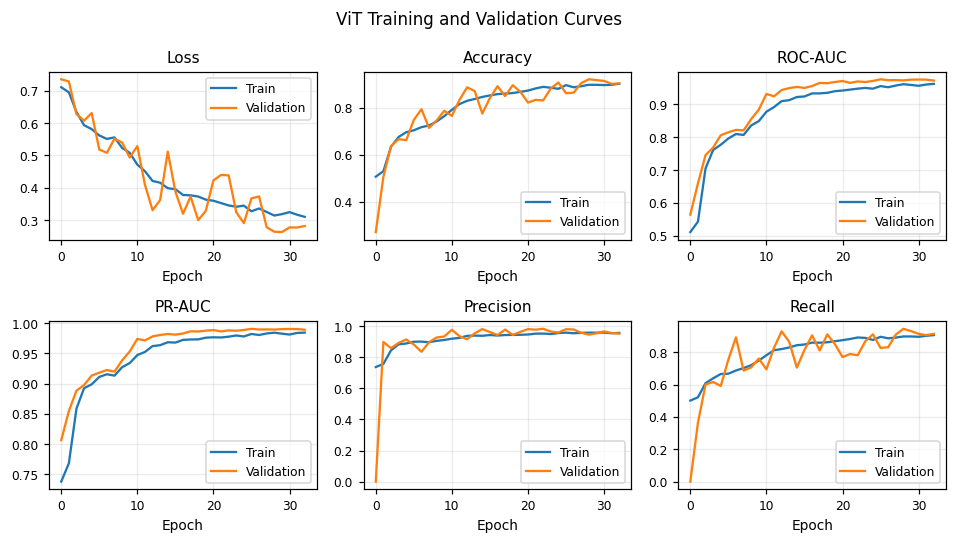

TRAINING HISTORY DATAFRAME


,accuracy,auc,loss,pr_auc,precision,recall,val_accuracy,val_auc,val_loss,val_pr_auc,val_precision,val_recall
28,0.8980,0.9609,0.3147,0.9844,0.9596,0.8980,0.9214,0.9726,0.2647,0.9895,0.9469,0.9454
29,0.8978,0.9587,0.3190,0.9828,0.9593,0.8980,0.9180,0.9747,0.2637,0.9903,0.9552,0.9314
30,0.8968,0.9561,0.3252,0.9813,0.9599,0.8960,0.9146,0.9751,0.2780,0.9905,0.9670,0.9142
31,0.8980,0.9599,0.3172,0.9840,0.9557,0.9020,0.9021,0.9748,0.2778,0.9904,0.9572,0.9064
32,0.9027,0.9620,0.3107,0.9845,0.9580,0.9064,0.9043,0.9720,0.2823,0.9893,0.9528,0.9142


In [ ]:
# ============================================================
# Training history — compact subplots + saved figure
# ============================================================

history_df = pd.DataFrame(history.history)
history_df.to_csv(
    OUTPUT_DIR / "history_dataframe.csv",
    index=False
)

metric_pairs = [
    ("loss", "val_loss", "Loss"),
    ("accuracy", "val_accuracy", "Accuracy"),
    ("auc", "val_auc", "ROC-AUC"),
    ("pr_auc", "val_pr_auc", "PR-AUC"),
    ("precision", "val_precision", "Precision"),
    ("recall", "val_recall", "Recall"),
]

fig, axes = plt.subplots(
    2, 3,
    figsize=(8.8, 5.0)
)

axes = axes.ravel()

for ax, (train_key, val_key, title) in zip(
    axes,
    metric_pairs
):
    if train_key in history.history:
        ax.plot(
            history.history[train_key],
            label="Train"
        )
        ax.plot(
            history.history[val_key],
            label="Validation"
        )
        ax.set_title(title)
        ax.set_xlabel("Epoch")
        ax.grid(alpha=0.25)
        ax.legend()

fig.suptitle(
    "ViT Training and Validation Curves",
    fontsize=11
)
fig.tight_layout()

save_figure(
    fig,
    "03_training_validation_curves.png"
)

plt.show()
plt.close(fig)

print("=" * 70)
print("TRAINING HISTORY DATAFRAME")
print("=" * 70)
display(history_df.tail().round(4))


## 14. Final Held-Out Test Evaluation

The test set has not been used for model selection. The following cells evaluate the final model on the held-out test split.


Loaded best checkpoint for final evaluation: /content/mydrive/MyDrive/Chest_XRay_ViT_Results_Optimized/best_vit_chest_xray.keras
257/257 ━━━━━━━━━━━━━━━━━━━━ 48s 178ms/step
Train: 4,099 labels / 4,099 predictions
55/55 ━━━━━━━━━━━━━━━━━━━━ 11s 191ms/step
Validation: 878 labels / 878 predictions
55/55 ━━━━━━━━━━━━━━━━━━━━ 207s 4s/step
Test: 879 labels / 879 predictions
VALIDATION-SELECTED OPERATING THRESHOLD
Optimal threshold (max validation F1): 0.0803
Validation precision at threshold    : 0.9343
Validation recall at threshold       : 0.9766
Validation F1 at threshold           : 0.9550
Saved figure: /content/mydrive/MyDrive/Chest_XRay_ViT_Results_Optimized/figures/04_validation_threshold_optimization.png


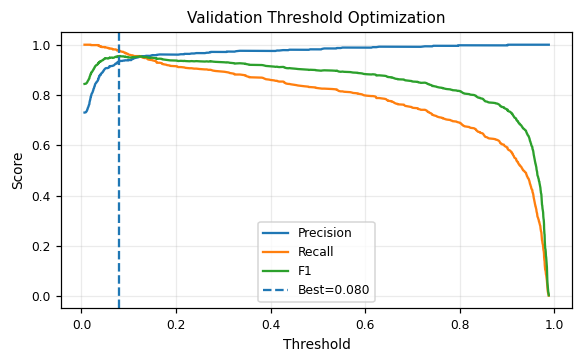

In [ ]:
# ============================================================
# FINAL EVALUATION SETUP
# ============================================================
# Reload the best validation-AUC checkpoint before final evaluation.
# custom_objects is required because the model contains custom ViT layers.
if best_model_path.exists():
    model = tf.keras.models.load_model(
        str(best_model_path),
        custom_objects={
            "Patches": Patches,
            "PatchEncoder": PatchEncoder,
        },
    )
    print("Loaded best checkpoint for final evaluation:", best_model_path)

# The classification threshold is selected ONLY on Validation.
# It is then frozen and applied to Train, Validation, and Test.
# This avoids tuning on the held-out test set.

def get_predictions(generator, split_name):
    if getattr(generator, "shuffle", False):
        raise ValueError(
            f"{split_name} generator must have shuffle=False "
            "for final evaluation."
        )

    generator.reset()

    probabilities = (
        model.predict(
            generator,
            verbose=1
        )
        .ravel()
    )

    # generator.classes may be a Python list in some Keras versions.
    y_true = np.asarray(
        generator.classes,
        dtype=int
    )

    if len(probabilities) != len(y_true):
        raise ValueError(
            f"Prediction/label length mismatch for {split_name}: "
            f"{len(probabilities)} predictions vs "
            f"{len(y_true)} labels"
        )

    print(
        f"{split_name}: "
        f"{len(y_true):,} labels / "
        f"{len(probabilities):,} predictions"
    )

    return y_true, probabilities


y_train_true, y_train_prob = get_predictions(
    train_eval_gen,
    "Train"
)

y_valid_true, y_valid_prob = get_predictions(
    valid_gen,
    "Validation"
)

y_test_true, y_test_prob = get_predictions(
    test_gen,
    "Test"
)

# ------------------------------------------------------------
# Validation-only threshold optimization
# ------------------------------------------------------------

val_precision_curve, val_recall_curve, val_thresholds = (
    precision_recall_curve(
        y_valid_true,
        y_valid_prob,
    )
)

if len(val_thresholds) == 0:
    raise ValueError(
        "No validation thresholds were generated."
    )

val_f1_curve = (
    2
    * val_precision_curve[:-1]
    * val_recall_curve[:-1]
    /
    (
        val_precision_curve[:-1]
        + val_recall_curve[:-1]
        + 1e-12
    )
)

best_idx = int(np.nanargmax(val_f1_curve))
OPTIMAL_THRESHOLD = float(
    val_thresholds[best_idx]
)

print("=" * 70)
print("VALIDATION-SELECTED OPERATING THRESHOLD")
print("=" * 70)
print(
    f"Optimal threshold (max validation F1): "
    f"{OPTIMAL_THRESHOLD:.4f}"
)
print(
    f"Validation precision at threshold    : "
    f"{val_precision_curve[best_idx]:.4f}"
)
print(
    f"Validation recall at threshold       : "
    f"{val_recall_curve[best_idx]:.4f}"
)
print(
    f"Validation F1 at threshold           : "
    f"{val_f1_curve[best_idx]:.4f}"
)

fig, ax = plt.subplots(figsize=(5.4, 3.4))

ax.plot(
    val_thresholds,
    val_precision_curve[:-1],
    label="Precision"
)

ax.plot(
    val_thresholds,
    val_recall_curve[:-1],
    label="Recall"
)

ax.plot(
    val_thresholds,
    val_f1_curve,
    label="F1"
)

ax.axvline(
    OPTIMAL_THRESHOLD,
    linestyle="--",
    label=f"Best={OPTIMAL_THRESHOLD:.3f}"
)

ax.set_xlabel("Threshold")
ax.set_ylabel("Score")
ax.set_title("Validation Threshold Optimization")
ax.grid(alpha=0.25)
ax.legend()

fig.tight_layout()

save_figure(
    fig,
    "04_validation_threshold_optimization.png"
)

plt.show()
plt.close(fig)

## 15. Confusion Matrix, Sensitivity, Specificity, and Classification Report

In [ ]:
# ============================================================
# METRICS TABLE FOR TRAIN / VALIDATION / TEST
# ============================================================

def calculate_binary_metrics(
    y_true,
    y_prob,
    threshold
):
    y_true = np.asarray(
        y_true,
        dtype=int
    )
    y_prob = np.asarray(
        y_prob,
        dtype=float
    )

    y_pred = (
        y_prob >= threshold
    ).astype(int)

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    )

    tn, fp, fn, tp = cm.ravel()

    specificity = (
        tn / (tn + fp)
        if (tn + fp)
        else np.nan
    )

    metrics = {
        "Accuracy": accuracy_score(
            y_true,
            y_pred
        ),
        "Precision": precision_score(
            y_true,
            y_pred,
            zero_division=0
        ),
        "Recall": recall_score(
            y_true,
            y_pred,
            zero_division=0
        ),
        "F1": f1_score(
            y_true,
            y_pred,
            zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            y_true,
            y_prob
        ),
        "PR-AUC": average_precision_score(
            y_true,
            y_prob
        ),
        "Specificity": specificity,
        "TN": int(tn),
        "FP": int(fp),
        "FN": int(fn),
        "TP": int(tp),
        "Threshold": float(threshold),
    }

    return metrics, y_pred, cm


split_inputs = {
    "Train": (
        y_train_true,
        y_train_prob
    ),
    "Validation": (
        y_valid_true,
        y_valid_prob
    ),
    "Test": (
        y_test_true,
        y_test_prob
    ),
}

all_metrics = []
predictions_by_split = {}
confusion_matrices = {}

for split_name, (
    y_true_split,
    y_prob_split
) in split_inputs.items():

    metrics, y_pred_split, cm_split = (
        calculate_binary_metrics(
            y_true_split,
            y_prob_split,
            OPTIMAL_THRESHOLD,
        )
    )

    metrics["Dataset"] = split_name
    all_metrics.append(metrics)

    predictions_by_split[
        split_name
    ] = y_pred_split

    confusion_matrices[
        split_name
    ] = cm_split


metrics_df = pd.DataFrame(
    all_metrics
).set_index("Dataset")

# Main requested DataFrame
classification_metrics_df = metrics_df[
    [
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
    ]
].copy()

print("\n" + "=" * 70)
print("TRAIN / VALIDATION / TEST PERFORMANCE")
print("=" * 70)

display(
    classification_metrics_df.round(4)
)

print("\nExtended metrics:")

display(
    metrics_df[
        [
            "Accuracy",
            "Precision",
            "Recall",
            "F1",
            "ROC-AUC",
            "PR-AUC",
            "Specificity",
            "Threshold",
        ]
    ].round(4)
)

classification_metrics_df.to_csv(
    OUTPUT_DIR
    / "accuracy_precision_recall_f1_all_splits.csv"
)

metrics_df.to_csv(
    OUTPUT_DIR
    / "all_metrics_train_validation_test.csv"
)


TRAIN / VALIDATION / TEST PERFORMANCE


,Accuracy,Precision,Recall,F1
Dataset,,,,
Train,0.9319,0.9355,0.9739,0.9543
Validation,0.9328,0.9343,0.9766,0.9550
Test,0.9204,0.9230,0.9719,0.9468



Extended metrics:


,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Specificity,Threshold
Dataset,,,,,,,,
Train,0.9319,0.9355,0.9739,0.9543,0.9807,0.9928,0.8186,0.0803
Validation,0.9328,0.9343,0.9766,0.9550,0.9759,0.9909,0.8143,0.0803
Test,0.9204,0.9230,0.9719,0.9468,0.9741,0.9903,0.7815,0.0803


## 16. ROC Curve

Saved figure: /content/mydrive/MyDrive/Chest_XRay_ViT_Results_Optimized/figures/05_confusion_matrices_train_validation_test.png


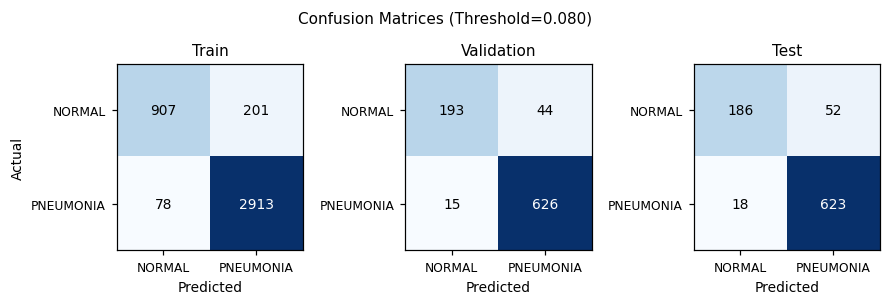


TRAIN CLASSIFICATION REPORT
              precision    recall  f1-score   support

      NORMAL     0.9208    0.8186    0.8667      1108
   PNEUMONIA     0.9355    0.9739    0.9543      2991

    accuracy                         0.9319      4099
   macro avg     0.9281    0.8963    0.9105      4099
weighted avg     0.9315    0.9319    0.9306      4099


VALIDATION CLASSIFICATION REPORT
              precision    recall  f1-score   support

      NORMAL     0.9279    0.8143    0.8674       237
   PNEUMONIA     0.9343    0.9766    0.9550       641

    accuracy                         0.9328       878
   macro avg     0.9311    0.8955    0.9112       878
weighted avg     0.9326    0.9328    0.9314       878


TEST CLASSIFICATION REPORT
              precision    recall  f1-score   support

      NORMAL     0.9118    0.7815    0.8416       238
   PNEUMONIA     0.9230    0.9719    0.9468       641

    accuracy                         0.9204       879
   macro avg     0.9174    0.8767    

In [ ]:
# ============================================================
# CONFUSION MATRICES — compact 1x3 subplot
# ============================================================

fig, axes = plt.subplots(
    1, 3,
    figsize=(8.2, 2.7)
)

for ax, split_name in zip(
    axes,
    ["Train", "Validation", "Test"]
):
    cm = confusion_matrices[
        split_name
    ]

    ax.imshow(
        cm,
        cmap="Blues"
    )

    ax.set_title(split_name)
    ax.set_xticks(
        [0, 1],
        CLASS_NAMES
    )
    ax.set_yticks(
        [0, 1],
        CLASS_NAMES
    )
    ax.set_xlabel("Predicted")

    if split_name == "Train":
        ax.set_ylabel("Actual")

    cutoff = (
        cm.max() / 2
        if cm.max() > 0
        else 0
    )

    for i in range(2):
        for j in range(2):
            ax.text(
                j,
                i,
                int(cm[i, j]),
                ha="center",
                va="center",
                fontsize=9,
                color=(
                    "white"
                    if cm[i, j] > cutoff
                    else "black"
                ),
            )

fig.suptitle(
    f"Confusion Matrices "
    f"(Threshold={OPTIMAL_THRESHOLD:.3f})",
    fontsize=10
)

fig.tight_layout()

save_figure(
    fig,
    "05_confusion_matrices_train_validation_test.png"
)

plt.show()
plt.close(fig)

# Classification reports
for split_name in [
    "Train",
    "Validation",
    "Test"
]:
    y_true_split, _ = split_inputs[
        split_name
    ]

    y_pred_split = predictions_by_split[
        split_name
    ]

    print("\n" + "=" * 70)
    print(
        f"{split_name.upper()} "
        "CLASSIFICATION REPORT"
    )
    print("=" * 70)

    print(
        classification_report(
            y_true_split,
            y_pred_split,
            target_names=CLASS_NAMES,
            digits=4,
            zero_division=0,
        )
    )

## 17. Save Test Predictions and Metrics

Saved figure: /content/mydrive/MyDrive/Chest_XRay_ViT_Results_Optimized/figures/06_roc_and_precision_recall_curves.png


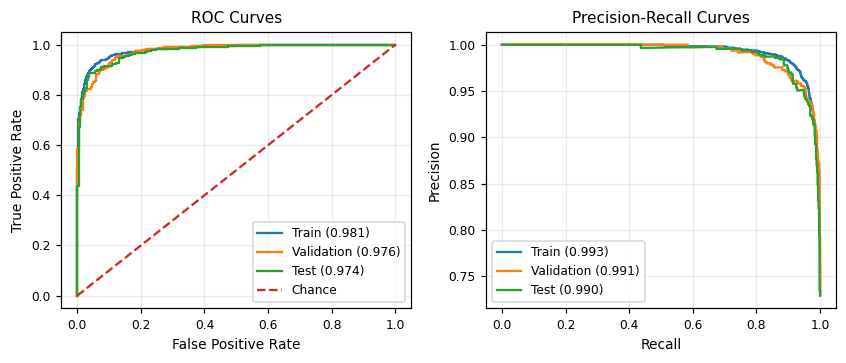

Saved: /content/mydrive/MyDrive/Chest_XRay_ViT_Results_Optimized/train_predictions.csv
Saved: /content/mydrive/MyDrive/Chest_XRay_ViT_Results_Optimized/validation_predictions.csv
Saved: /content/mydrive/MyDrive/Chest_XRay_ViT_Results_Optimized/test_predictions.csv

Saved summary tables:
/content/mydrive/MyDrive/Chest_XRay_ViT_Results_Optimized/accuracy_precision_recall_f1_all_splits.csv
/content/mydrive/MyDrive/Chest_XRay_ViT_Results_Optimized/all_metrics_train_validation_test.csv
Best model: /content/mydrive/MyDrive/Chest_XRay_ViT_Results_Optimized/best_vit_chest_xray.keras
Figures: /content/mydrive/MyDrive/Chest_XRay_ViT_Results_Optimized/figures
Validation-selected threshold: 0.0803


In [ ]:
# ============================================================
# ROC + PRECISION-RECALL CURVES + SAVE PREDICTIONS
# ============================================================

fig, axes = plt.subplots(
    1, 2,
    figsize=(7.8, 3.4)
)

# ROC
for split_name, (
    y_true_split,
    y_prob_split
) in split_inputs.items():

    fpr, tpr, _ = roc_curve(
        y_true_split,
        y_prob_split
    )

    auc_value = roc_auc_score(
        y_true_split,
        y_prob_split
    )

    axes[0].plot(
        fpr,
        tpr,
        label=(
            f"{split_name} "
            f"({auc_value:.3f})"
        )
    )

axes[0].plot(
    [0, 1],
    [0, 1],
    "--",
    label="Chance"
)

axes[0].set_xlabel(
    "False Positive Rate"
)
axes[0].set_ylabel(
    "True Positive Rate"
)
axes[0].set_title(
    "ROC Curves"
)
axes[0].legend()
axes[0].grid(alpha=0.25)

# Precision-Recall
for split_name, (
    y_true_split,
    y_prob_split
) in split_inputs.items():

    precision_vals, recall_vals, _ = (
        precision_recall_curve(
            y_true_split,
            y_prob_split,
        )
    )

    ap_value = average_precision_score(
        y_true_split,
        y_prob_split
    )

    axes[1].plot(
        recall_vals,
        precision_vals,
        label=(
            f"{split_name} "
            f"({ap_value:.3f})"
        )
    )

axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title(
    "Precision-Recall Curves"
)
axes[1].legend()
axes[1].grid(alpha=0.25)

fig.tight_layout()

save_figure(
    fig,
    "06_roc_and_precision_recall_curves.png"
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# Save per-image predictions
# ------------------------------------------------------------

for split_name, split_df in [
    ("Train", df_train),
    ("Validation", df_valid),
    ("Test", df_test),
]:
    y_true_split, y_prob_split = (
        split_inputs[split_name]
    )

    y_pred_split = (
        predictions_by_split[
            split_name
        ]
    )

    predictions_df = (
        split_df.copy()
        .reset_index(drop=True)
    )

    predictions_df[
        "true_label"
    ] = y_true_split

    predictions_df[
        "pneumonia_probability"
    ] = y_prob_split

    predictions_df[
        "predicted_label"
    ] = y_pred_split

    predictions_df[
        "predicted_class"
    ] = [
        CLASS_NAMES[int(x)]
        for x in y_pred_split
    ]

    predictions_df[
        "threshold_used"
    ] = OPTIMAL_THRESHOLD

    predictions_path = (
        OUTPUT_DIR
        / f"{split_name.lower()}_predictions.csv"
    )

    predictions_df.to_csv(
        predictions_path,
        index=False
    )

    print("Saved:", predictions_path)

print("\nSaved summary tables:")
print(
    OUTPUT_DIR
    / "accuracy_precision_recall_f1_all_splits.csv"
)
print(
    OUTPUT_DIR
    / "all_metrics_train_validation_test.csv"
)
print("Best model:", best_model_path)
print("Figures:", FIGURE_DIR)
print(
    f"Validation-selected threshold: "
    f"{OPTIMAL_THRESHOLD:.4f}"
)


# Summary and Next Experiments

This version is designed as a stronger **from-scratch ViT baseline**.

For additional experiments, change **one variable at a time** and compare validation AUC:

1. `PATCH_SIZE`: compare 16 vs 32.
2. `TRANSFORMER_LAYERS`: compare 4 vs 6.
3. `PROJECTION_DIM`: compare 64 vs 96.
4. `LEARNING_RATE`: compare `3e-4` vs `1e-4`.
5. `BATCH_SIZE`: compare 16 vs 32 if GPU memory allows.
6. Try grayscale images only if you also change the model input to one channel.
7. For the highest likely performance, compare this from-scratch model against a **pretrained** ViT, DenseNet, EfficientNet, or ConvNeXt model.

### Interpretation note
Accuracy alone is not enough for pneumonia classification. Pay close attention to:
- **Sensitivity/recall**: how many pneumonia cases are detected.
- **Specificity**: how many normal cases are correctly identified.
- **ROC-AUC**: threshold-independent discrimination.
- The confusion matrix and the effect of changing the classification threshold.

This notebook is intended for research/educational evaluation, not clinical deployment.


## Optimization summary

This notebook uses **conservative image augmentation** during training and **class weights** to address class imbalance. Validation and test images are not augmented. Final Train metrics are computed using a separate non-augmented, non-shuffled generator.

All major plots are compact and saved automatically to the `figures/` folder. Accuracy, Precision, Recall, and F1 are available in `classification_metrics_df` and are saved to CSV. The threshold is selected using Validation only, then frozen for Train/Validation/Test evaluation.

In [ ]:
# ============================================================
# FINAL RUN SUMMARY / SANITY CHECKS
# ============================================================
print("=" * 70)
print("FINAL NOTEBOOK SUMMARY")
print("=" * 70)
print(f"Input image shape       : ({IMAGE_SIZE}, {IMAGE_SIZE}, 3)")
print(f"Patch size              : {PATCH_SIZE} x {PATCH_SIZE}")
print(f"Number of ViT patches   : {NUM_PATCHES}")
print(f"Best model path         : {best_model_path}")
print(f"Results directory       : {OUTPUT_DIR}")
print(f"Operating threshold     : {OPTIMAL_THRESHOLD:.4f}")
print("Final classification metrics:")
display(classification_metrics_df.round(4))


FINAL NOTEBOOK SUMMARY
Input image shape       : (128, 128, 3)
Patch size              : 16 x 16
Number of ViT patches   : 64
Best model path         : /content/mydrive/MyDrive/Chest_XRay_ViT_Results_Optimized/best_vit_chest_xray.keras
Results directory       : /content/mydrive/MyDrive/Chest_XRay_ViT_Results_Optimized
Operating threshold     : 0.0803
Final classification metrics:


,Accuracy,Precision,Recall,F1
Dataset,,,,
Train,0.9319,0.9355,0.9739,0.9543
Validation,0.9328,0.9343,0.9766,0.9550
Test,0.9204,0.9230,0.9719,0.9468


Batch image shape: (16, 128, 128, 3)
Expected image size: (128, 128, 3)


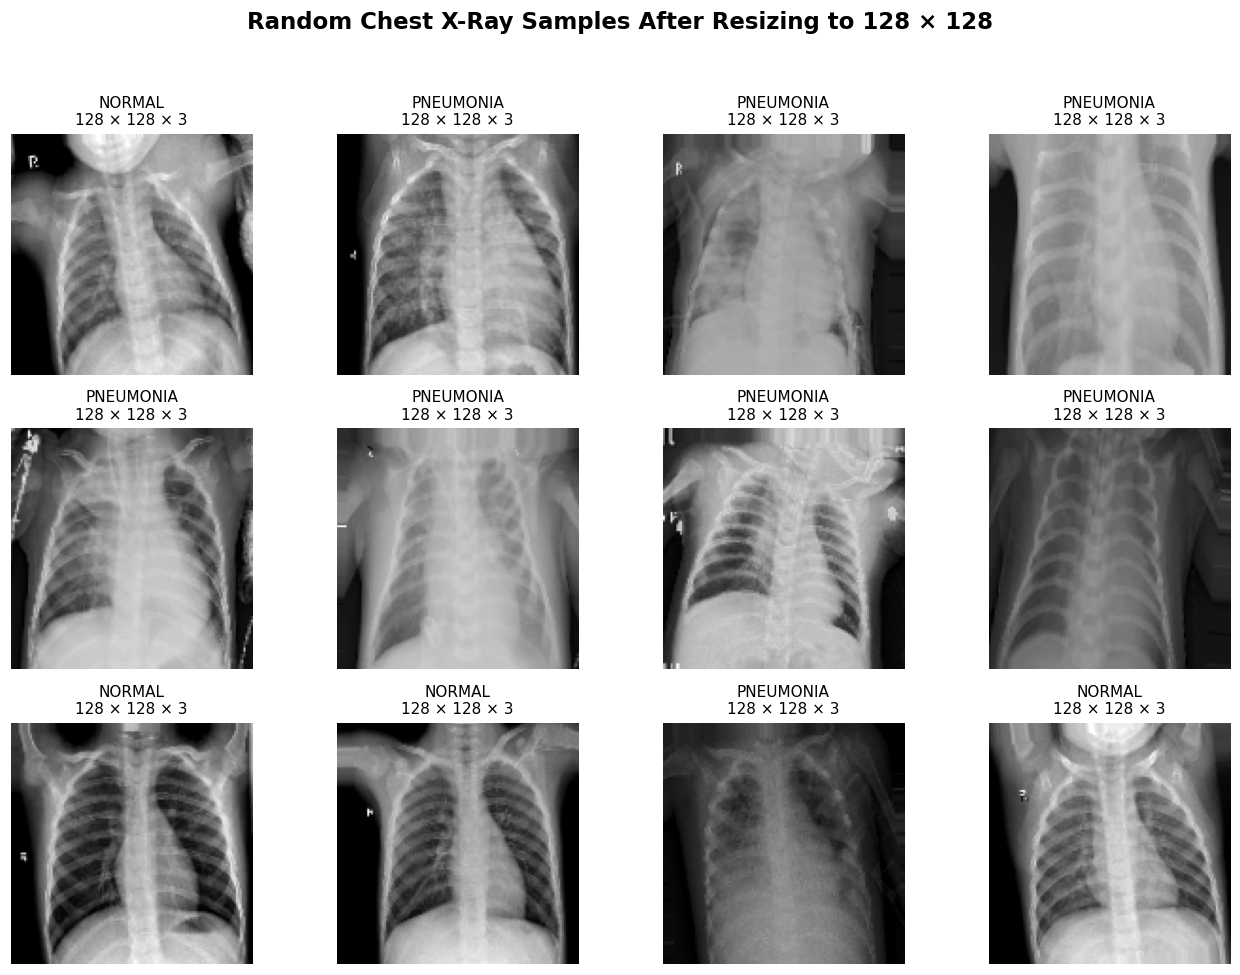


Figure saved successfully: 01_random_resized_samples.png
All displayed images have size: 128 × 128 × 3


In [ ]:
# ============================================================
# RANDOM SAMPLES AFTER IMAGE RESIZING / PREPROCESSING
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import os

# Number of random images to display
NUM_SAMPLES = 12

# Output filename
OUTPUT_FILE = "01_random_resized_samples.png"

# ------------------------------------------------------------
# Get one batch of already resized/preprocessed images
# train_gen produces images with:
#     target_size = (IMAGE_SIZE, IMAGE_SIZE)
# ------------------------------------------------------------
train_gen.reset()

images_batch, labels_batch = next(train_gen)

# Convert to float32 for safe Matplotlib visualization
images_batch = np.asarray(images_batch, dtype=np.float32)

print("Batch image shape:", images_batch.shape)
print("Expected image size:", (IMAGE_SIZE, IMAGE_SIZE, 3))

# ------------------------------------------------------------
# Select random images from the batch
# ------------------------------------------------------------
num_available = len(images_batch)
num_samples = min(NUM_SAMPLES, num_available)

random_indices = np.random.choice(
    num_available,
    size=num_samples,
    replace=False
)

# ------------------------------------------------------------
# Create figure
# ------------------------------------------------------------
cols = 4
rows = int(np.ceil(num_samples / cols))

fig, axes = plt.subplots(
    rows,
    cols,
    figsize=(12, 3 * rows)
)

axes = np.array(axes).reshape(-1)

for ax in axes:
    ax.axis("off")

for plot_index, image_index in enumerate(random_indices):

    image = images_batch[image_index]

    # --------------------------------------------------------
    # Safely normalize image for visualization
    # If generator already rescales to [0,1], nothing changes.
    # --------------------------------------------------------
    image_to_show = image.copy()

    if image_to_show.max() > 1.0:
        image_to_show = image_to_show / 255.0

    image_to_show = np.clip(image_to_show, 0.0, 1.0)

    # --------------------------------------------------------
    # Determine class label
    # --------------------------------------------------------
    label = labels_batch[image_index]

    # Binary classification
    if np.ndim(label) == 0 or np.size(label) == 1:
        class_index = int(np.asarray(label).reshape(-1)[0])

    # Categorical classification
    else:
        class_index = int(np.argmax(label))

    # Get class name if available
    if hasattr(train_gen, "class_indices"):
        index_to_class = {
            value: key
            for key, value in train_gen.class_indices.items()
        }

        class_name = index_to_class.get(
            class_index,
            str(class_index)
        )
    else:
        class_name = str(class_index)

    # --------------------------------------------------------
    # Display image
    # --------------------------------------------------------
    axes[plot_index].imshow(image_to_show)

    axes[plot_index].set_title(
        f"{class_name}\n"
        f"{image.shape[0]} × {image.shape[1]} × {image.shape[2]}",
        fontsize=10
    )

    axes[plot_index].axis("off")


# ------------------------------------------------------------
# Main figure title
# ------------------------------------------------------------
fig.suptitle(
    f"Random Chest X-Ray Samples After Resizing to "
    f"{IMAGE_SIZE} × {IMAGE_SIZE}",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout(rect=[0, 0, 1, 0.95])


# ------------------------------------------------------------
# Save figure
# ------------------------------------------------------------
fig.savefig(
    OUTPUT_FILE,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"\nFigure saved successfully: {OUTPUT_FILE}")
print(f"All displayed images have size: "
      f"{IMAGE_SIZE} × {IMAGE_SIZE} × 3")